# StockTwits: from the platform dump to daily counts

This notebook follows the StockTwits data through the pipeline (`pipeline/01_extract_stocktwits.py` to `pipeline/05_daily_counts.py`), with the counts of the stored outputs and hand-made examples of every rule. The notebook runs on the outputs in `data/pipeline/` and reads only stats files and aggregate counts. Every example text is hand-made; no real post, post id or account id is shown. Run it from `code/notebooks/` after the pipeline has run.

In [1]:
%matplotlib inline
import importlib
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

CODE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(CODE))
from pipeline import config, rules as R  # noqa: E402

OUT = config.OUT_DIR          # data/pipeline/ (never printed: it is a local path)
con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
R.register_udfs(con)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def stats(*parts):
    """A stats file of the pipeline, by its path under data/pipeline/."""
    return json.loads(OUT.joinpath(*parts).read_text())


def src(*parts):
    """SQL source for Parquet files under data/pipeline/ (glob patterns allowed)."""
    return f"read_parquet('{OUT.joinpath(*parts)}', hive_partitioning = false)"


def q(sql):
    return con.execute(sql).df()


def annotate(texts, own=None):
    """Hand-made texts through the computed columns of step 2 (rules.annotate_sql).
    Evidence reads `text` (the full text), structure reads `own` (the author's own words)."""
    own = own or texts
    rows = ", ".join(f"({i}, {R.dq(t)}, {R.dq(o)})" for i, (t, o) in enumerate(zip(texts, own)))
    con.execute(f"CREATE OR REPLACE TEMP TABLE hand_made AS SELECT * FROM (VALUES {rows}) v(i, text, own)")
    con.execute("CREATE OR REPLACE TEMP TABLE annotated AS " +
                R.annotate_sql("SELECT i, text, own FROM hand_made", "text", "own") + " ORDER BY i")
    return q("SELECT * FROM annotated ORDER BY i")


def gates(extra=""):
    """The coin gate (rules.coin_gate) and the market rule on the last annotated examples."""
    coins = ", ".join(f"{R.coin_gate(c)} AS {c.lower()}" for c in R.COINS)
    any_coin = " OR ".join(R.coin_gate(c) for c in R.COINS)
    return q(f"SELECT text, {coins}, {R.market_rule(any_coin)} AS market{extra} FROM annotated ORDER BY i")


def daily_summary(platform):
    """Posts per UTC day after the bot filter, per series (step 5)."""
    d = q(f"""SELECT series, CAST(count(*) AS BIGINT) AS days, CAST(sum(n_posts) AS BIGINT) AS posts,
                     round(avg(n_posts), 1) AS mean_per_day, median(n_posts) AS median_per_day,
                     CAST(min(n_posts) AS BIGINT) AS min_per_day, CAST(max(n_posts) AS BIGINT) AS max_per_day,
                     CAST(count_if(n_posts = 0) AS BIGINT) AS days_without_posts
              FROM {src('panel', 'daily_counts.parquet')} WHERE platform = '{platform}' GROUP BY 1""")
    order = ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET", "CRYPTO_SET"]
    d["k"] = [order.index(s) if s in order else 99 for s in d.series]
    return d.sort_values(["k", "series"]).drop(columns="k").set_index("series")


def weekly_plot(platform, title):
    # Twitter: a day without any capture is missing, not a day without posts (its count is 0 in the table;
    # how the attention variable treats such days is decision D14). Those days are left out of the weekly
    # mean, so a week without any capture shows as a gap in the line.
    keep = "TRUE" if platform != "twitter" else (
        f"day IN (SELECT utc_day FROM {src('twitter', 'units', 'twitter_coverage_utc.parquet')} WHERE minutes_utc > 0)")
    w = q(f"""SELECT series, date_trunc('week', day) AS week, avg(n_posts) FILTER (WHERE {keep}) AS posts_per_day
              FROM {src('panel', 'daily_counts.parquet')}
              WHERE platform = '{platform}' AND series IN ('BTC', 'ETH', 'BNB', 'XRP', 'DOGE', 'MARKET')
              GROUP BY 1, 2 ORDER BY 2""")
    fig, ax = plt.subplots(figsize=(9, 4))
    for s in ["BTC", "ETH", "BNB", "XRP", "DOGE", "MARKET"]:
        x = w[w.series == s]
        ax.plot(x.week, x.posts_per_day, label=s, linewidth=1)
    ax.set_yscale("log")
    ax.set_ylabel("posts per day (weekly mean, log scale)")
    ax.set_title(title)
    ax.legend(ncol=6, fontsize=8, frameon=False)
    fig.tight_layout()
    return fig


## Step 1: extract (`01_extract_stocktwits.py`)

The full StockTwits dump (2008-05-27 to 2024-01-02, 749 CSV files) was reduced once, on a VM, to the messages of the window 1 Aug 2019 – 31 Jan 2023 (UTC), one row per message id, one Parquet file per month ("Stage A", kept on Google Drive). No coin decision is taken there. The months as step 2 read them:

In [2]:
months = sorted(p.name.split("=")[1] for p in OUT.joinpath("stocktwits", "coarse").glob("month=*"))
rows = []
for m in months:
    c = stats("stocktwits", "coarse", f"month={m}", "_stats.json")["counts"]
    rows.append({"month": m, "Stage A messages": c["rows_in"], "kept": c["rows_out"],
                 "admitted by text": c["admitted_by_text"], "admitted by symbol": c["admitted_by_symbol"]})
st = pd.DataFrame(rows).set_index("month")
print(f"{len(st)} months; {st['Stage A messages'].sum():,} messages in Stage A; {st['kept'].sum():,} kept "
      f"({100 * st['kept'].sum() / st['Stage A messages'].sum():.1f}%)")
st.iloc[[0, 1, 2, -3, -2, -1]]

42 months; 306,828,630 messages in Stage A; 27,312,845 kept (8.9%)


,Stage A messages,kept,admitted by text,admitted by symbol
month,,,,
2019-08,3364527,138348,133200,46575
2019-09,2955330,111413,107240,37366
2019-10,2942756,119755,114847,38671
2022-11,5188892,484285,400008,249428
2022-12,4684583,320030,273718,123390
2023-01,4958249,419916,329653,213014


## Step 2: which messages are kept, and their computed columns (`02_filter_stocktwits.py`)

A message is kept if its body matches the inclusion pattern (any coin term of tiers 1-3, or a word of the two context lists; on the raw body, links included, so the table stays a superset of every later rule) **or** its author-typed symbol list holds a crypto symbol (1-20 capital letters, digits, dots or hyphens followed by `.X`). Hand-made symbol lists:

In [3]:
f2 = importlib.import_module("pipeline.02_filter_stocktwits")
q(f"""SELECT symbol_list, {f2.ST_SYMS} AS parsed_symbols,
             regexp_matches(coalesce(symbol_list, ''), {R.dq(f2.ST_SYMBOL_ENTRY)}) AS admitted_by_symbol
      FROM (VALUES ('[''BTC.X'', ''AAPL'']'), ('[''ERENYEAGERINU.X'']'), ('[''BTC'']'), ('[''AAPL'', ''TSLA'']'),
                   (CAST(NULL AS VARCHAR))) v(symbol_list)""")

,symbol_list,parsed_symbols,admitted_by_symbol
0,"['BTC.X', 'AAPL']","[BTC.X, AAPL]",True
1,['ERENYEAGERINU.X'],[ERENYEAGERINU.X],True
2,['BTC'],[BTC],False
3,"['AAPL', 'TSLA']","[AAPL, TSLA]",False
4,NaN,[],False


The plain symbol `BTC` (without `.X`) does not admit a message on its own; once a message is admitted by its text, it counts for BTC in step 4. Each kept message then gets the computed columns of `rules.py` (StockTwits has no quote lines, so the full text and the own words are the same). Hand-made examples:

In [4]:
ex = annotate(["$BTC.X to the moon", "ETH Zurich is a university", "eth gas fees are crazy today",
              "buying more altcoins on the dip", "https://example.com/bitcoin", "the stock market is up"])
ex[["text", "hit_btc_t1", "hit_btc_t2", "hit_eth_t1", "hit_eth_t3", "ctx_crypto", "coin_only_in_link",
    "is_url_only", "cashtags", "n_ambiguous_terms"]]

,text,hit_btc_t1,hit_btc_t2,hit_eth_t1,hit_eth_t3,ctx_crypto,coin_only_in_link,is_url_only,cashtags,n_ambiguous_terms
0,$BTC.X to the moon,True,False,False,False,False,False,False,[BTC],1
1,ETH Zurich is a university,False,False,False,True,False,False,False,[],0
2,eth gas fees are crazy today,False,False,False,True,False,False,False,[],0
3,buying more altcoins on the dip,False,False,False,False,True,False,False,[],0
4,https://example.com/bitcoin,False,False,False,False,False,True,True,[],0
5,the stock market is up,False,False,False,False,False,False,False,[],0


## Step 3: bot filter (`03_bot_filter.py`)

The same rules as on the other platforms, each on all messages with its own flag, each using only data up to the message's UTC day. StockTwits has no user names and no AutoModerator, so those rules do not apply; the keyword rule counts 2 of its 4 remaining criteria. The crypto ticker list of the keyword rule is every StockTwits `.X` symbol, so StockTwits runs first.

| Rule | Criterion | Source |
|---|---|---|
| keyword | at least 2 of: give-away words; pump with join/register; > 5 hashtags; > 5 crypto tickers | Kraaijeveld & De Smedt (2020), Electronic Markets (2025) |
| campaign | a fingerprint posted by >= 20 accounts on one UTC day forms a group; a member account is a bot that day if >= 60% of its window carry fingerprints found in the windows of >= 3 of the group's accounts | Chen & Subramanian (2018) |
| template | more than half of the pairs in an account's window are near-copies (difflib ratio > 0.7) | Electronic Markets (2025) |
| invite | Telegram/Discord invite link: flag only, never in `bot_any` | Nizzoli et al. (2020) |

In [5]:
f = stats("stocktwits", "bot", "post_flags.parquet.stats.json")["counts"]
rules = pd.DataFrame({"posts flagged": f["flags"], "flagged by this rule only": f.get("flag_only_this_rule", {})}).astype("Int64")
rules.index.name = "rule"
print(f"{f['posts']:,} posts; campaign groups: {f['campaign']['groups']:,}; "
      f"template bot account-days: {f['template']['bot_account_days']:,} of {f['template']['account_days']:,}")
rules

27,312,845 posts; campaign groups: 507; template bot account-days: 57,981 of 9,959,543


,posts flagged,flagged by this rule only
rule,,
bot_keyword,317,292
bot_campaign,545891,46433
bot_template,926885,427402
invite_link,154303,<NA>
bot_any,973610,<NA>


## Step 4: series (`04_series_stocktwits.py`)

**Coin gate:** a message counts for a coin if its text holds a tier-1 or tier-2 term of the coin, or it carries the coin's symbol (for BTC also the plain symbol `BTC`), or its text holds a tier-3 term together with a clearly crypto word other than the coin's own tier-3 words; BNB counts by tier 1, tier 2 or its symbol only. A message counts for every coin it names.  
**Market:** a message that counts for no coin enters the market series if it carries another crypto `.X` symbol or at least one clearly crypto word. The gate on the hand-made texts above (text only; the symbol part of the gate is not shown):

In [6]:
gates()

,text,btc,eth,bnb,xrp,doge,market
0,$BTC.X to the moon,True,False,False,False,False,False
1,ETH Zurich is a university,False,False,False,False,False,False
2,eth gas fees are crazy today,False,False,False,False,False,False
3,buying more altcoins on the dip,False,False,False,False,False,True
4,https://example.com/bitcoin,False,False,False,False,False,False
5,the stock market is up,False,False,False,False,False,False


In [7]:
a = stats("stocktwits", "panel", "assignment.parquet.stats.json")["counts"]
fc, after = a["flag_counts"], a["series_after_bot_pass"]
series = pd.DataFrame({"posts in the series": {s: fc[f"in_{s}"] for s in after},
                       "after the bot filter": after})
series["removed by the bot filter"] = series["posts in the series"] - series["after the bot filter"]
series.index = [s.upper() for s in series.index]
series
print(f"equity-only messages (symbols, none crypto): {fc['equity_only']:,}; replies whose parent names a coin "
      f"(robustness A42): {sum(fc[f'reply_parent_{c}'] for c in ['btc', 'eth', 'bnb', 'xrp', 'doge']):,}")

equity-only messages (symbols, none crypto): 5,620,117; replies whose parent names a coin (robustness A42): 522,291


## Step 5: daily counts (`05_daily_counts.py`)

In [8]:
daily_summary("stocktwits")

,days,posts,mean_per_day,median_per_day,min_per_day,max_per_day,days_without_posts
series,,,,,,,
BTC,1280,4512968,3525.8,2526.0,313,29075,0
ETH,1280,890955,696.1,425.0,29,6952,0
BNB,1280,108446,84.7,33.0,0,3579,13
XRP,1280,439820,343.6,177.0,17,7096,0
DOGE,1280,2721447,2126.1,558.0,0,76284,1
MARKET,1280,9358252,7311.1,4288.0,162,97517,0
CRYPTO_SET,1280,17388493,13584.8,8428.0,612,112841,0


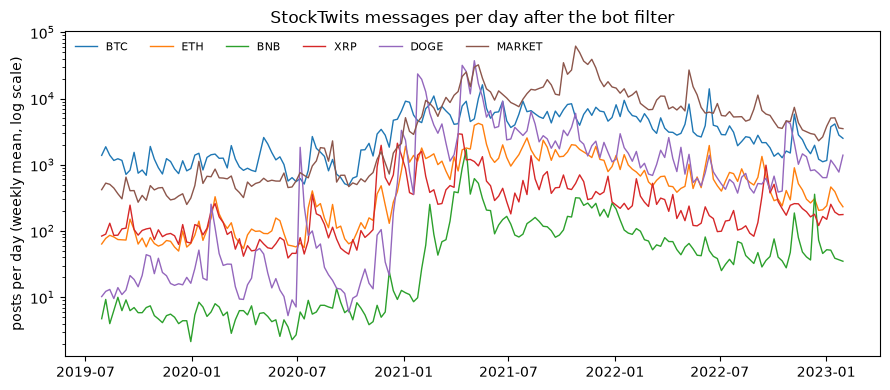

In [9]:
fig = weekly_plot("stocktwits", "StockTwits messages per day after the bot filter")